STEP 1: Setup

Figure Parameters

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N2": "#031A6B", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic Cells": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial Cells": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # allback
    "Unknown": "#808080"#grey
}

Loading Samples

In [2]:
import os
import re
import pandas as pd
import numpy as np
import scanpy as sc
from collections import defaultdict

def get_condition(fname: str) -> str:
    if "HER2" in fname:                          return "HER2"
    if "-ER-"  in fname or "_ER-"  in fname:     return "ER"
    if "-TN-"  in fname or "_TN-"  in fname:     return "TN"
    if "-N-"  in fname or "_N-"  in fname: return "N"
    return "unknown"

In [3]:
#loading files
data_dir = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"

adatas          = []#keeping all AnnData objects in memory
summary_list    = []#per-sample stats
condition_hvgs  = defaultdict(lambda: None)#HVG intersection per condition
skipped         = []

In [4]:
for fname in sorted(os.listdir(data_dir)):
    if not fname.endswith(".h5ad") or fname.startswith("._"):
        continue

    path      = os.path.join(data_dir, fname)
    condition = get_condition(fname)

    try:
        adata = sc.read_h5ad(path)
    except Exception as e:
        skipped.append(f"{fname}: ERROR – {e}")
        continue

    #Summary statistics
    full_patient = adata.obs["patient_id"].iloc[0]
    #Removing GSM prefix if present
    patient = re.sub(r"^GSM\d+_", "", full_patient)
    #Extracting condition
    match = re.match(r"^(HER2|TN|ER|N)", patient)

    if match:
        condition_code = match.group(1)
    else:
        condition_code = "UNKNOWN"

    print(condition_code)
    summary_list.append({
        "patient_id":   patient,
        "condition":    condition_code,
        "n_cells":      adata.n_obs,
        "mean_counts":  adata.obs["total_counts"].mean(),
        "var_counts":   adata.obs["total_counts"].var(),
    })

    #HVG intersection
    if "highly_variable" in adata.var.columns:
        hvgs = set(adata.var_names[adata.var["highly_variable"]].tolist())
        condition_hvgs[condition] = (
            hvgs if condition_hvgs[condition] is None
            else condition_hvgs[condition] & hvgs
        )
        print(f"Loaded: {fname}  [{condition}]  →  {adata.shape},  {len(hvgs)} HVGs")
    else:
        skipped.append(f"{fname}: no highly_variable column")
        print(f"Loaded: {fname}  [{condition}]  →  {adata.shape}  (no HVGs)")

    adatas.append(adata)

N
Loaded: GSM4909253_N-PM0092-Total.h5ad  [N]  →  (4389, 33538),  2000 HVGs
N
Loaded: GSM4909254_N-PM0019-Total.h5ad  [N]  →  (5870, 33538),  2000 HVGs
N
Loaded: GSM4909257_N-PM0095-Total.h5ad  [N]  →  (4447, 33538),  2000 HVGs
N
Loaded: GSM4909261_N-PM0230-Total.h5ad  [N]  →  (2982, 33538),  2000 HVGs
N
Loaded: GSM4909263_N-MH0064-Total.h5ad  [N]  →  (1561, 33538),  2000 HVGs
N
Loaded: GSM4909265_N-PM0233-Total.h5ad  [N]  →  (4778, 33538),  2000 HVGs
N
Loaded: GSM4909266_N-MH0169-Total.h5ad  [N]  →  (4133, 33538),  2000 HVGs
N
Loaded: GSM4909268_N-MH0023-Total.h5ad  [N]  →  (6454, 33538),  2000 HVGs
N
Loaded: GSM4909270_N-PM0342-Total.h5ad  [N]  →  (8647, 33538),  2000 HVGs
N
Loaded: GSM4909271_N-MH288-Total.h5ad  [N]  →  (1976, 33538),  2000 HVGs
N
Loaded: GSM4909272_N-MH0021-Total.h5ad  [N]  →  (2339, 33538),  2000 HVGs
N
Loaded: GSM4909274_N-MH275-Total.h5ad  [N]  →  (1526, 33538),  2000 HVGs
N
Loaded: GSM4909276_N-PM0372-Total.h5ad  [N]  →  (3495, 33538),  2000 HVGs
TN
Loaded: GSM

In [5]:
print(f"Processed samples: {len(summary_list)}")
print(f"Skipped samples: {len(skipped)}")

if len(summary_list):
    print(pd.DataFrame(summary_list).columns)
else:
    print("summary_list is empty")

print(skipped[:10])

Processed samples: 45
Skipped samples: 0
Index(['patient_id', 'condition', 'n_cells', 'mean_counts', 'var_counts'], dtype='object')
[]


In [6]:
#summary DataFrame
summary_df = (
    pd.DataFrame(summary_list)
    .sort_values(["condition", "patient_id"])
    .reset_index(drop=True)
)

In [7]:
#HVG report
print(f"\nLoaded {len(adatas)} samples,  {len(skipped)} skipped")
if skipped:
    print("\nSkipped:")
    for s in skipped: print(f"  {s}")

print("\n=== HVG intersection per condition ===")
final_hvgs_union        = set()
final_hvgs_intersection = None

for cond, hvgs in condition_hvgs.items():
    if hvgs is None:
        print(f"  {cond}: no HVGs found")
        continue
    print(f"  {cond}: {len(hvgs)} HVGs")
    final_hvgs_union.update(hvgs)
    final_hvgs_intersection = (
        hvgs if final_hvgs_intersection is None
        else final_hvgs_intersection & hvgs
    )

print(f"\nFinal gene set options:")
print(f"  Union across conditions:        {len(final_hvgs_union)} genes")
print(f"  Intersection across conditions: {len(final_hvgs_intersection or set())} genes")


Loaded 45 samples,  0 skipped

=== HVG intersection per condition ===
  N: 990 HVGs
  TN: 730 HVGs
  HER2: 914 HVGs
  ER: 651 HVGs

Final gene set options:
  Union across conditions:        1386 genes
  Intersection across conditions: 424 genes


STEP 2: Concatenation

In [8]:
sample_keys = [re.sub(r"^GSM\d+_", "", a.obs["patient_id"].iloc[0]) for a in adatas]
adata_full = sc.concat(adatas, join="inner", label="sample", keys=sample_keys, index_unique="-")
print(adata_full.layers.keys())
print(adata.layers.keys())

KeysView(Layers with keys: counts, log1p)
KeysView(Layers with keys: counts, log1p)


In [9]:
adata_full.var["highly_variable"] = (
    adata_full.var_names.isin(final_hvgs_union)
)

print(
    f"HVGs matched: "
    f"{adata_full.var['highly_variable'].sum()} / "
    f"{len(final_hvgs_union)}"
)

HVGs matched: 1386 / 1386


Inspection Before Integration

In [10]:
adata_pre = adata_full[:, adata_full.var["highly_variable"]].copy()
adata_pre.X = adata_pre.layers["log1p"]
print(f"Shape after HVG subset: {adata_pre.shape}") #cells × intersection genes

sc.pp.scale(adata_pre, max_value=10, zero_center=False)
sc.tl.pca(adata_pre, n_comps=20, zero_center=False)

#batch correction before neighbors
sc.pp.neighbors(adata_pre, use_rep="X_pca", n_pcs=20, n_neighbors=15)
sc.tl.umap(adata_pre)

Shape after HVG subset: (251616, 1386)


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


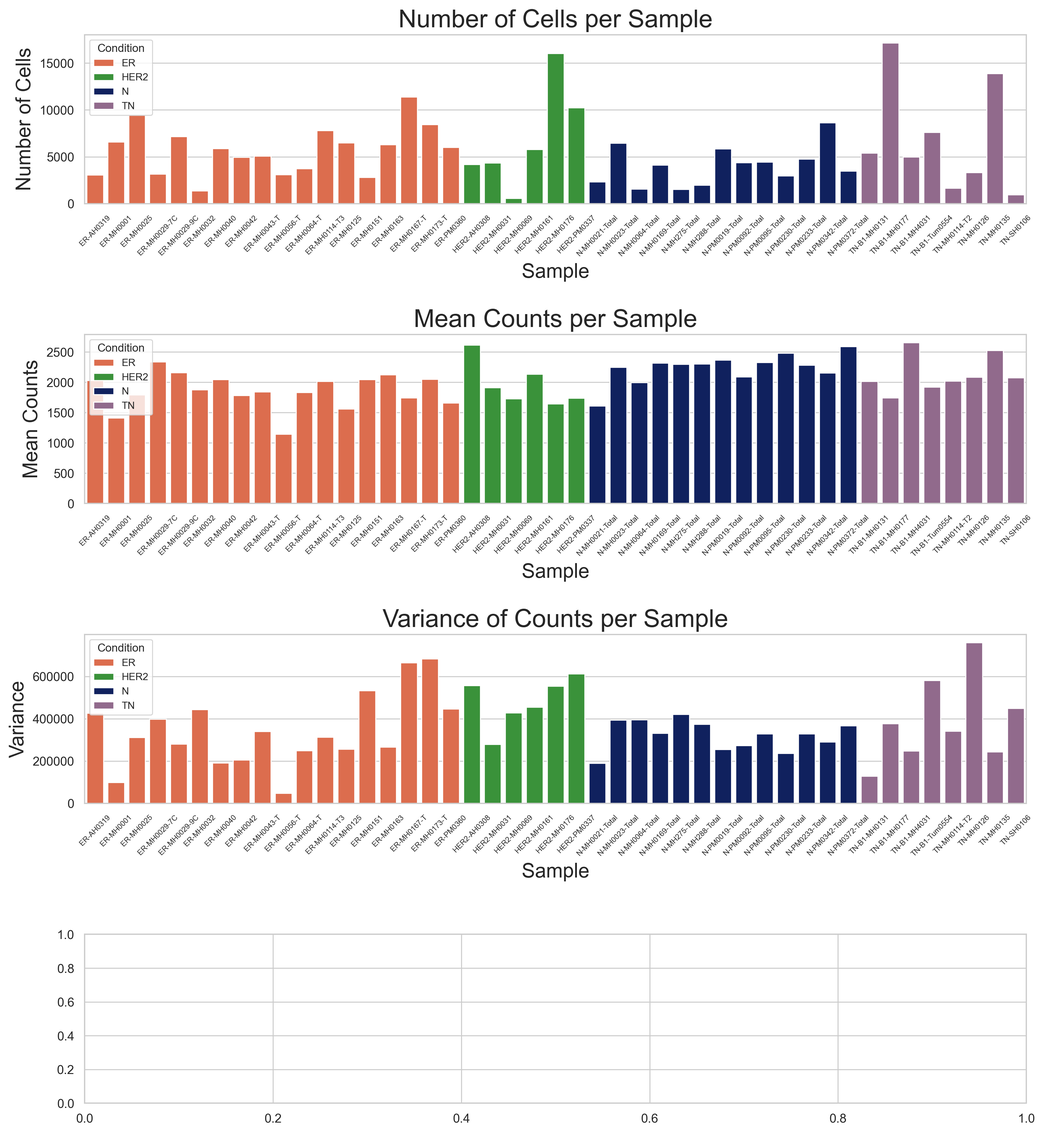

In [11]:
batch_key = "patient_id"
adata.uns[batch_key + "_colors"] = ["#1f77b4", "#C2AFF0", "#2ca02c", "#d62728", "#FFD166", "#031A6B"]  # N2
fig, axes = plt.subplots(4, 1, figsize=(12, 13))

#1a Barplot: number of cells per sample
sns.barplot(
    x="patient_id", y="n_cells", hue="condition", data=summary_df,
    dodge=False, ax=axes[0], palette=condition_palette)
axes[0].set_title("Number of Cells per Sample")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Number of Cells")
axes[0].tick_params(axis='x', rotation=45, labelsize=6)
axes[0].legend(title="Condition", fontsize=8, title_fontsize=9)

#1b Barplot: mean counts
summary_df_melt_mean = summary_df.melt(
    id_vars=["patient_id", "condition"],
    value_vars=["mean_counts"],
    var_name="metric",
    value_name="value")
sns.barplot(
    x="patient_id", y="value", hue="condition", data=summary_df_melt_mean,
    dodge=False, ax=axes[1], palette=condition_palette)
axes[1].set_title("Mean Counts per Sample")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Mean Counts")
axes[1].tick_params(axis='x', rotation=45, labelsize=6)
axes[1].legend(title="Condition", fontsize=8, title_fontsize=9)

#1c Barplot: variance of counts
summary_df_melt_var = summary_df.melt(
    id_vars=["patient_id", "condition"],
    value_vars=["var_counts"],
    var_name="metric",
    value_name="value")
sns.barplot(
    x="patient_id", y="value", hue="condition", data=summary_df_melt_var,
    dodge=False, ax=axes[2], palette=condition_palette)
axes[2].set_title("Variance of Counts per Sample")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Variance")
axes[2].tick_params(axis='x', rotation=45, labelsize=6)
axes[2].legend(title="Condition", fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.savefig(rf"{data_dir}/../Figures/1_Before_Concat.png", dpi=300, bbox_inches="tight")
plt.show()

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_45909/3736025392.py:3: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


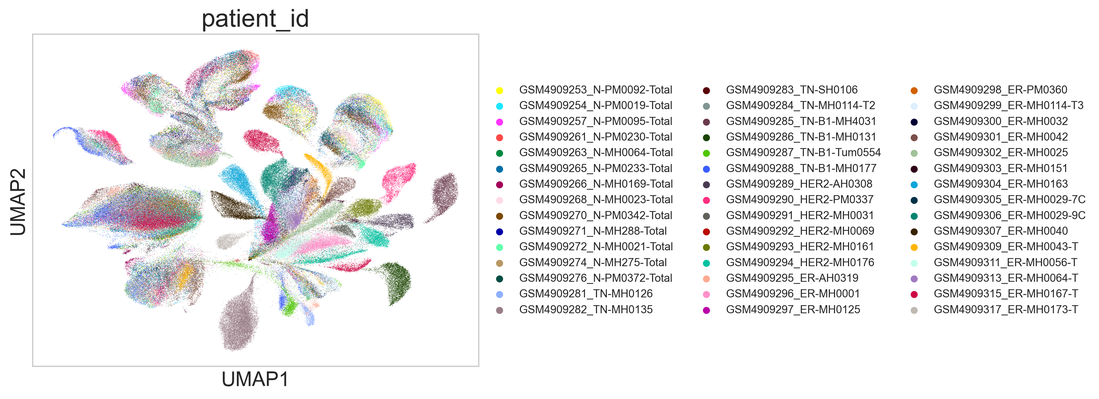

In [12]:
#1d UMAP pre-integration
sc.pl.umap(adata_pre, color="patient_id", show=False)
plt.tight_layout()
plt.savefig(rf"{data_dir}/../Figures/2_Before_Concat.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
del adata_pre

STEP 3: Integration

In [14]:
import scvi
import gc
adata_scvi = adata_full[:, adata_full.var["highly_variable"]].copy()

In [15]:
print(adata_scvi.layers["counts"][:5, :5].toarray())
print(adata_scvi.obs[["patient_id", "sample"]].drop_duplicates())

[[0. 1. 1. 0. 0.]
 [0. 0. 2. 0. 0.]
 [0. 0. 1. 1. 0.]
 [0. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0.]]
                                                  patient_id          sample
AAACCTGAGACTAGGC-1-N-PM0092-Total  GSM4909253_N-PM0092-Total  N-PM0092-Total
AAACCTGAGCACACAG-1-N-PM0019-Total  GSM4909254_N-PM0019-Total  N-PM0019-Total
AAACCCAAGTGGAAAG-1-N-PM0095-Total  GSM4909257_N-PM0095-Total  N-PM0095-Total
AAACCTGAGCCCTAAT-1-N-PM0230-Total  GSM4909261_N-PM0230-Total  N-PM0230-Total
AAACCTGAGCTGCGAA-1-N-MH0064-Total  GSM4909263_N-MH0064-Total  N-MH0064-Total
AAACCTGCAAGTAGTA-1-N-PM0233-Total  GSM4909265_N-PM0233-Total  N-PM0233-Total
AAACCCAAGTTGTCGT-1-N-MH0169-Total  GSM4909266_N-MH0169-Total  N-MH0169-Total
AAACCTGAGAACAATC-1-N-MH0023-Total  GSM4909268_N-MH0023-Total  N-MH0023-Total
AAACCCAAGTCTAGCT-1-N-PM0342-Total  GSM4909270_N-PM0342-Total  N-PM0342-Total
AAACCTGAGGTGGGTT-1-N-MH288-Total    GSM4909271_N-MH288-Total   N-MH288-Total
AAACCTGAGAGCTATA-1-N-MH0021-Total  GSM4909272_N-MH0021-Total  

In [16]:
scvi.model.SCVI.setup_anndata(adata_scvi, layer="counts", batch_key="patient_id")

model = scvi.model.SCVI(adata_scvi, n_latent=30, n_layers=2, gene_likelihood="zinb")
model.train(accelerator="mps", early_stopping=True, early_stopping_patience=20)

#storing latent representation
adata_scvi.obsm["X_scVI"] = model.get_latent_representation()
model.save("scvi_model/", overwrite=True)
del model
gc.collect()

#writing back to full adata
adata_full.obsm["X_scVI"] = adata_scvi.obsm["X_scVI"]
del adata_scvi
gc.collect()

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and tr

Epoch 32/32: 100%|██████████| 32/32 [13:12<00:00, 28.81s/it, v_num=1, train_loss=1.2e+3] 

`Trainer.fit` stopped: `max_epochs=32` reached.


Epoch 32/32: 100%|██████████| 32/32 [13:12<00:00, 24.78s/it, v_num=1, train_loss=1.2e+3]


0

In [17]:
#Neighbors and UMAP on scVI latent space
sc.pp.neighbors(adata_full, use_rep="X_scVI")
sc.tl.leiden(adata_full, key_added="scVI_leiden", resolution=1)
sc.tl.umap(adata_full)

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_45909/2742621972.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_full, key_added="scVI_leiden", resolution=1)


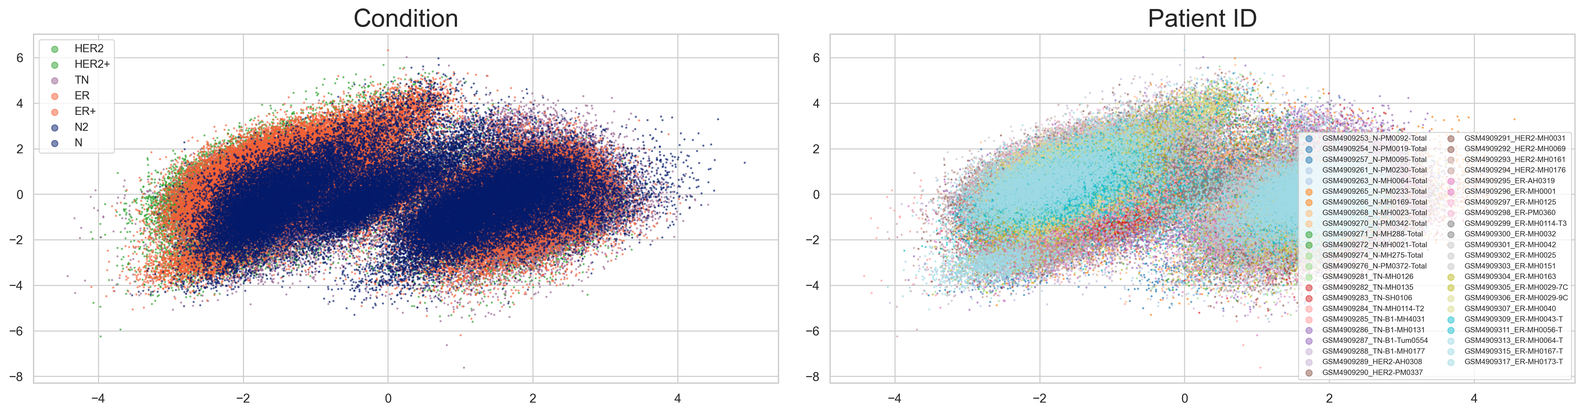

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit_transform(adata_full.obsm["X_scVI"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

#0a Color by condition
conditions = adata_full.obs["condition"].astype("category")
for cond, color in condition_palette.items():
    mask = conditions == cond
    axes[0].scatter(pca[mask, 0], pca[mask, 1], s=1, label=cond, color=color, alpha=0.5)
axes[0].set_title("Condition")
axes[0].legend(markerscale=5)

#0b Color by patient
patients = adata_full.obs["patient_id"].astype("category")
colors = plt.cm.tab20(np.linspace(0, 1, len(patients.cat.categories)))
for i, pat in enumerate(patients.cat.categories):
    mask = patients == pat
    axes[1].scatter(pca[mask, 0], pca[mask, 1], s=1, label=pat, color=colors[i], alpha=0.5)
axes[1].set_title("Patient ID")
axes[1].legend(markerscale=5, fontsize=6, ncol=2)
del pca
gc.collect()
plt.tight_layout()
plt.show()

Saving Progress

In [ ]:
import anndata as ad
import scipy.sparse as sp
import gc

#sanity checks
assert "counts" in adata_full.layers
assert "X_umap" in adata_full.obsm
assert "X_scVI" in adata_full.obsm

#creating lightweight object
adata_minimal = ad.AnnData(
    X=sp.csr_matrix(adata_full.layers["counts"]),  # raw counts only
    obs=adata_full.obs.copy(),
    var=adata_full.var.copy()
)

#storing embeddings
adata_minimal.obsm["X_umap"] = adata_full.obsm["X_umap"]
adata_minimal.obsm["X_scVI"] = adata_full.obsm["X_scVI"]

#storing clusters
adata_minimal.obs["scVI_leiden"] = (
    adata_full.obs["scVI_leiden"].copy()
)

#keeping counts explicitly named
adata_minimal.layers["counts"] = adata_minimal.X.copy()

#saving integrated adata
adata_minimal.write_h5ad(rf"{data_dir}/../h5ad_saves/adata_minimal.h5ad", compression="gzip")
print(f"Saved: {adata_minimal.shape}")

# Cleanup
del adata_full
del adata_minimal
gc.collect()

In [ ]:
deliberate break -> Restart Kernel

STEP 4: Celltype Annotation

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

#loading files
data_dir = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic Cells": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial Cells": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # allback
    "Unknown": "#808080"#grey
}

In [2]:
import pandas as pd
import numpy as np
import scanpy as sc
import scipy.sparse as sp
import psutil

adata = sc.read_h5ad(rf"{data_dir}/../h5ad_saves/adata_minimal.h5ad")
print(f"Available RAM: {psutil.virtual_memory().available / 1e9:.1f} GB")
print(adata)

Available RAM: 1.3 GB
AnnData object with n_obs × n_vars = 251616 × 33538
    obs: 'patient_id', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'sex_gene_expression', 'scDblFinder_score', 'scDblFinder_class', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'size_factors', 'sample', 'scVI_leiden'
    var: 'highly_variable'
    obsm: 'X_scVI', 'X_umap'
    layers: 'counts'


In [3]:
#adata.obs["condition"] = adata.obs["condition"].str.replace("^N$", "N1", regex=True)
adata.obs["condition"] = adata.obs["condition"].str.replace("^ER$", "ER+", regex=True)
adata.obs["condition"] = adata.obs["condition"].str.replace("^HER2$", "HER2+", regex=True)
condition_order = ["TN", "ER+", "HER2+", "N"]

adata.obs["condition"] = pd.Categorical(adata.obs["condition"], categories=condition_order, ordered=True)

In [4]:
unexpected = set(adata.obs["condition"].unique()) - set(condition_order)
print(unexpected)#should be empty set()

set()


<function matplotlib.pyplot.show(close=None, block=None)>

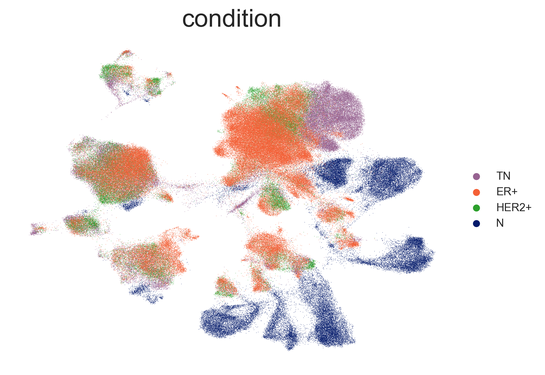

In [5]:
#2 UMAP coloured by condition
sc.pl.umap(adata, color=["condition"], palette=condition_palette, frameon=False, show=False)
savefig = plt.savefig(rf"{data_dir}/../Figures/2_Cond_ID.png", dpi=300, bbox_inches="tight")
plt.show

done


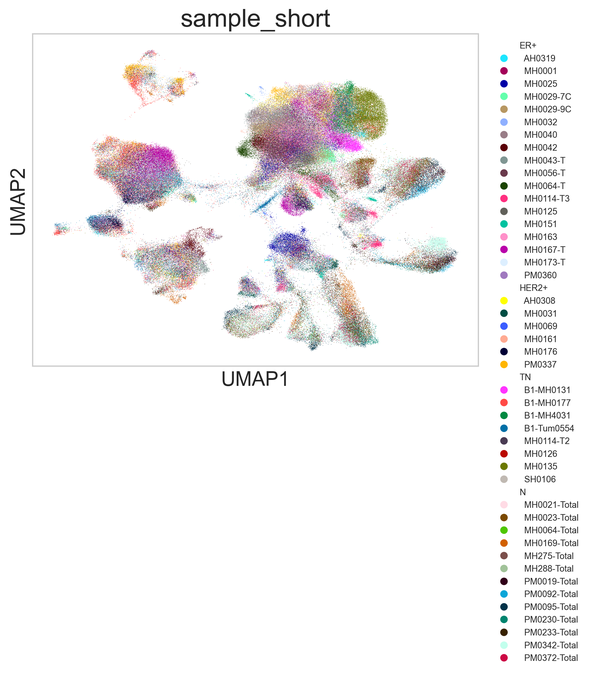

In [6]:
adata.obs["sample_short"] = (
    adata.obs["sample"]
    .astype(str)
    .str.strip()
    .str.replace(".h5ad", "", regex=False)
    .str.split("_", n=1).str[-1]
    .str.replace(r"^(TN|ER|HER2|N)-", "", regex=True)
    .astype("category")
)
print("done")
from matplotlib.lines import Line2D

#3 UMAP coloured by sample with short sample names
#plotting UMAP without default legend
sc.pl.umap( adata, color="sample_short", legend_loc=None,show=False)
ax = plt.gca()

#extract colours assigned by Scanpy
samples = adata.obs["sample_short"].cat.categories
colors  = adata.uns["sample_short_colors"]

sample_to_color = dict(zip(samples, colors))

#building grouped legend
handles = []

for condition in ["ER+", "HER2+", "TN", "N"]:

    #header (invisible marker)
    handles.append(Line2D([], [], linestyle="none", label=f"{condition}",color="black"))

    #samples belonging to this condition
    cond_samples = (adata.obs.loc[adata.obs["condition"] == condition, "sample_short"].unique())

    for sample in sorted(cond_samples):

        handles.append(Line2D([], [], marker="o", linestyle="none", markersize=6,markerfacecolor=sample_to_color[sample], markeredgecolor="none", label=f"  {sample}"))

#drawing legend
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(rf"{data_dir}/../Figures/3_All_Sample.png", dpi=300, bbox_inches="tight")
plt.show()

a) Basic Marker Genes

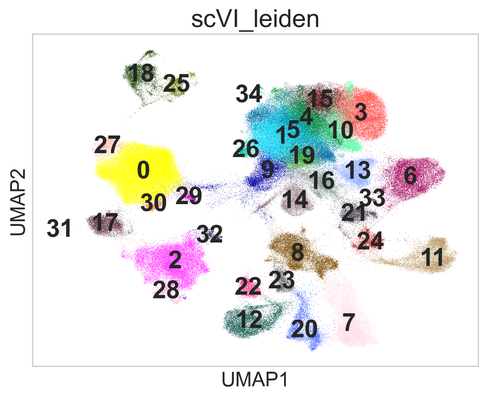

In [7]:
sc.pl.umap(adata, color="scVI_leiden", legend_loc="on data", show=False)
plt.savefig(rf"{data_dir}/../Figures/4_Cluster_Numbers.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
#keys: cell types or populations, values: lists of marker genes
marker_genes = {
    "T Cells": ["PTPRC", "CD3D", "CD3E"],
    "B Cells": ["CD79A", "CD74", "MS4A1"],
    "Macrophages": ["CD68", "CD14", "ITGAM"],
    "Fibroblasts": ["COL1A1", "CXCL12", "MYL9"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHG1"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],#CLDN5
    "Mast Cells": ["KIT", "CPA3", "TPSAB1"],
    "Dendritic Cells": ["ITGAX", "HLA-DRA", "CD83"],
    "Epithelial Cells": ["KRT19", "EPCAM",  "GAPDH"],
    "Tumour Cells": ["TP63", "KRT17"],
    "NK Cells": ["NKG7", "GNLY", "KLRD1"]
}

In [9]:
marker_genes_in_data = {}
for ct, markers in marker_genes.items():
    markers_found = []
    for marker in markers:
        if marker in adata.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [10]:
B_plasma_cts = [
    "T Cells",
    "B Cells",
    "Macrophages",
    "Fibroblasts",
    "Plasma Cells",
    "Endothelial Cells",
    "Mast Cells",
    "Dendritic Cells",
    "NK Cells"
]

T CELLS:


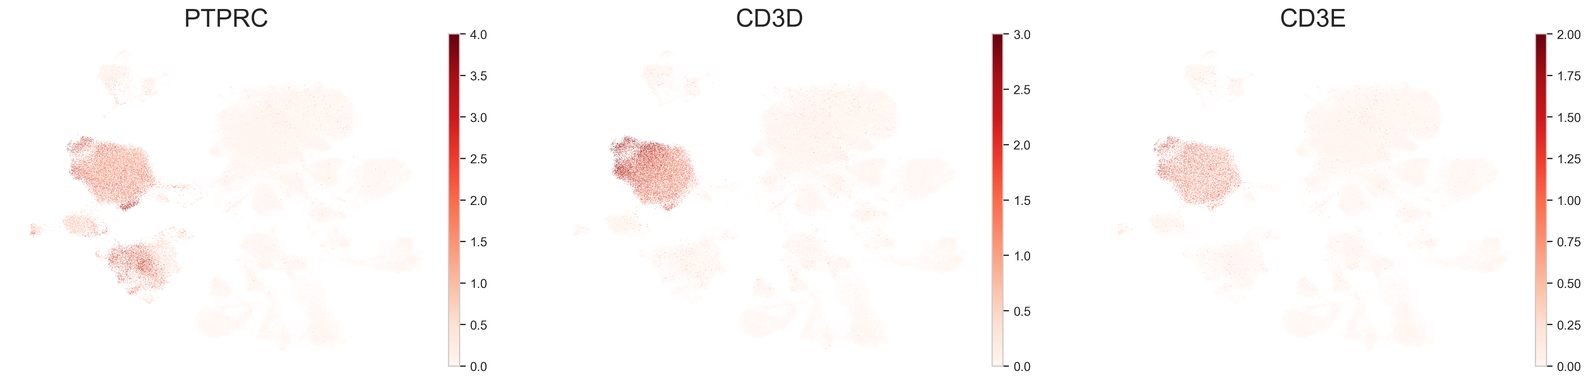





B CELLS:


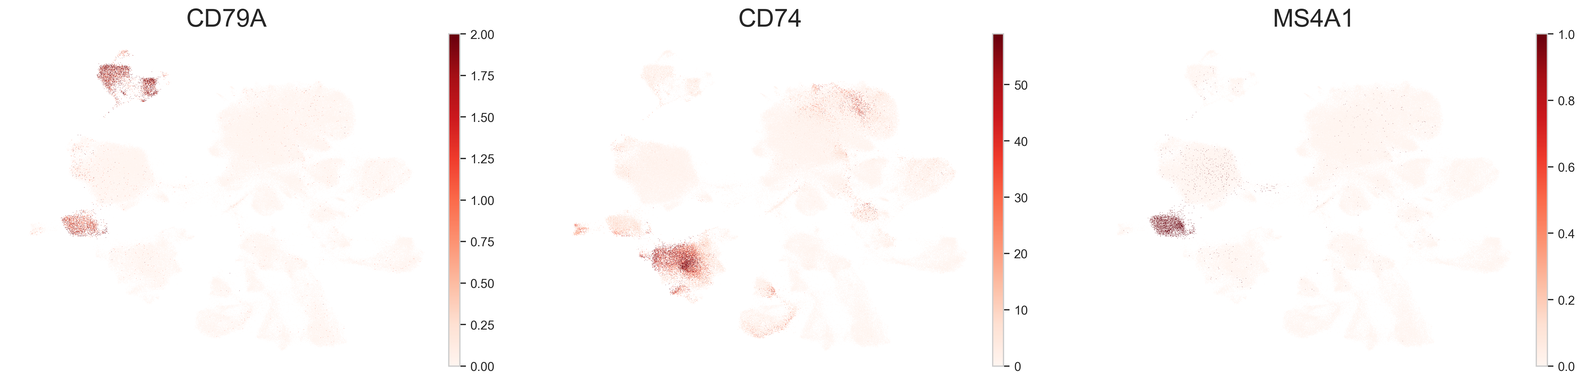





MACROPHAGES:


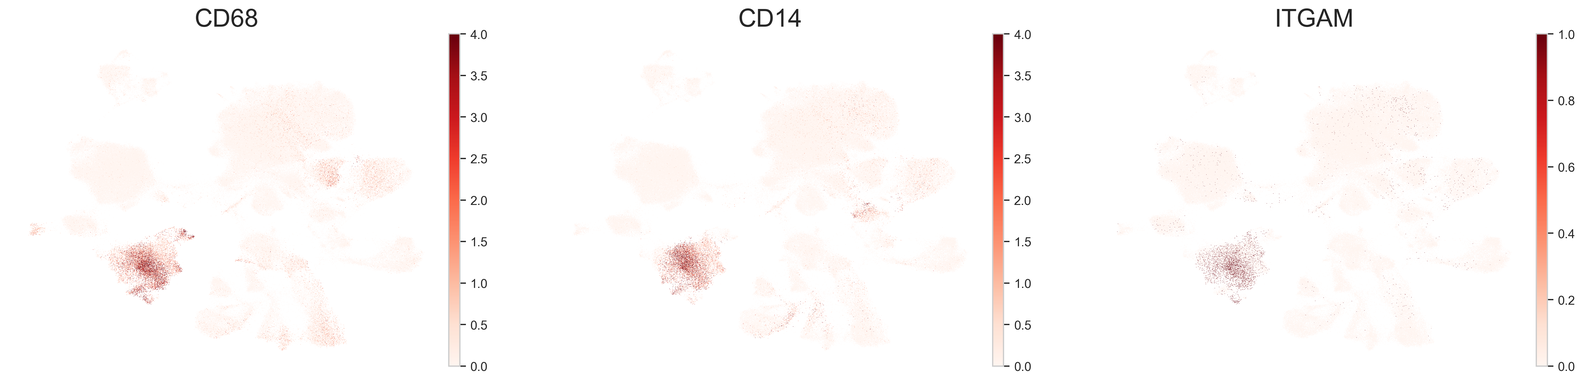





FIBROBLASTS:


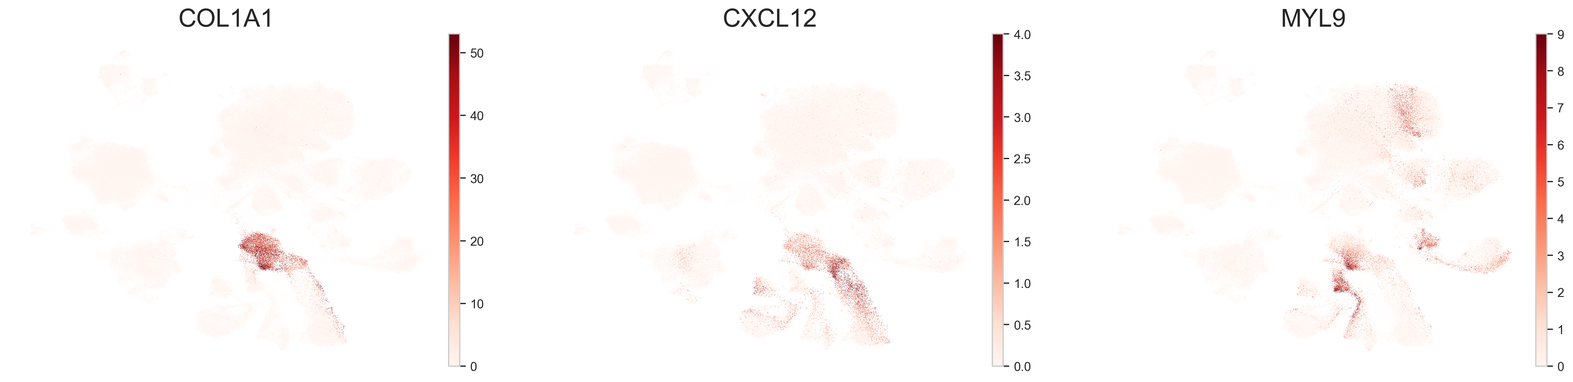





PLASMA CELLS:


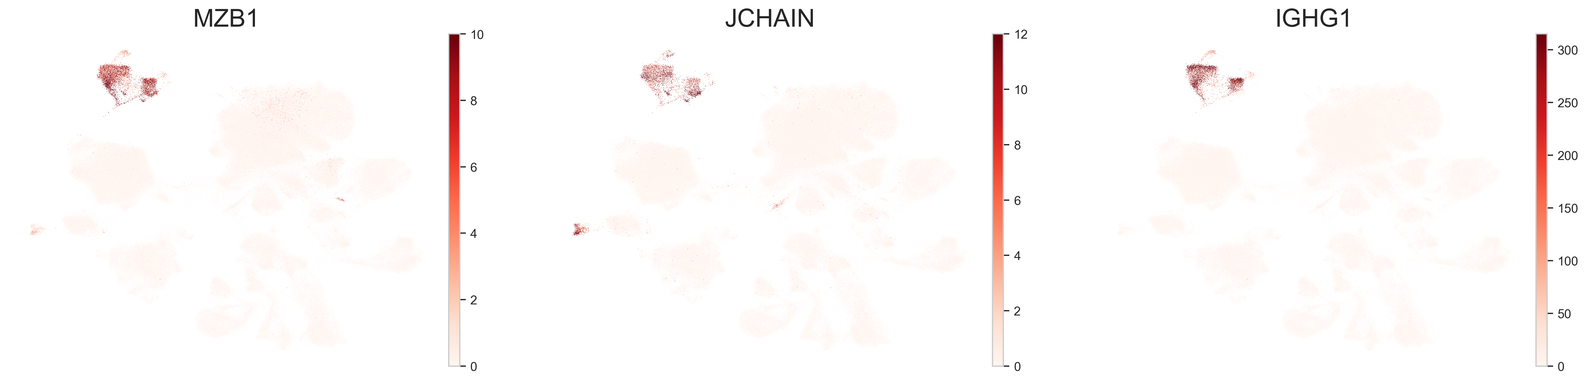





ENDOTHELIAL CELLS:


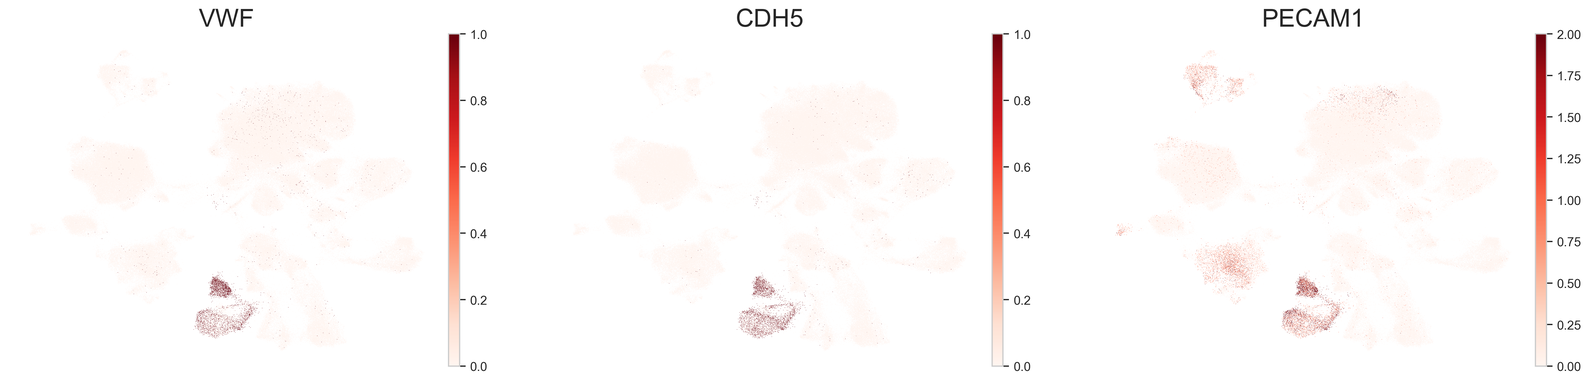





MAST CELLS:


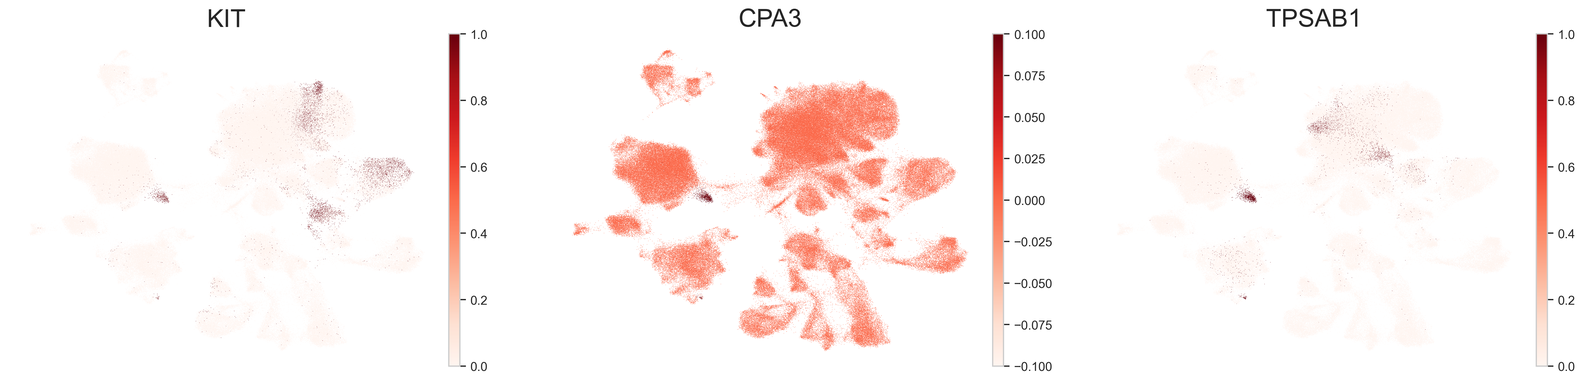





DENDRITIC CELLS:


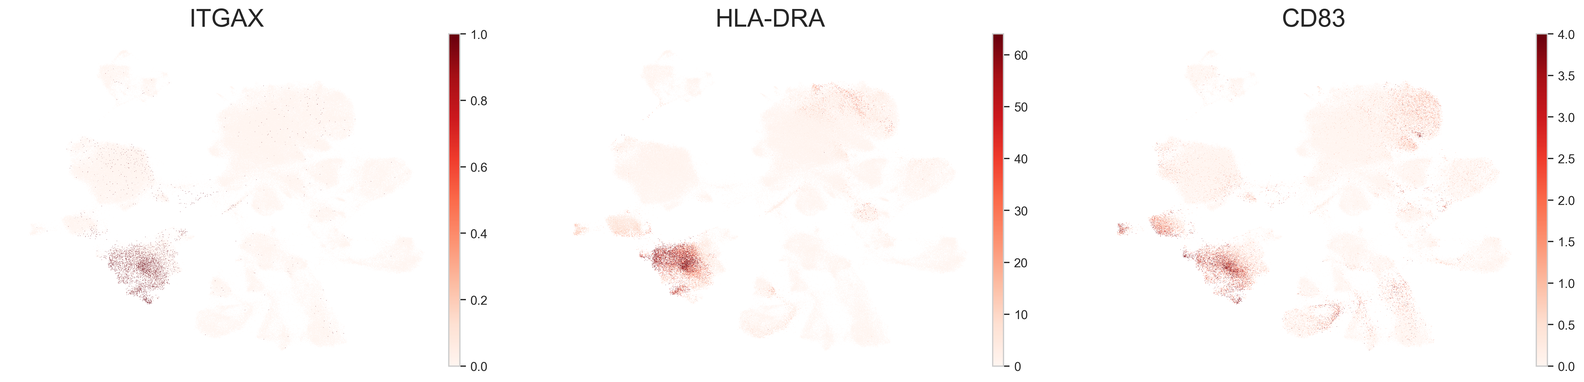





NK CELLS:


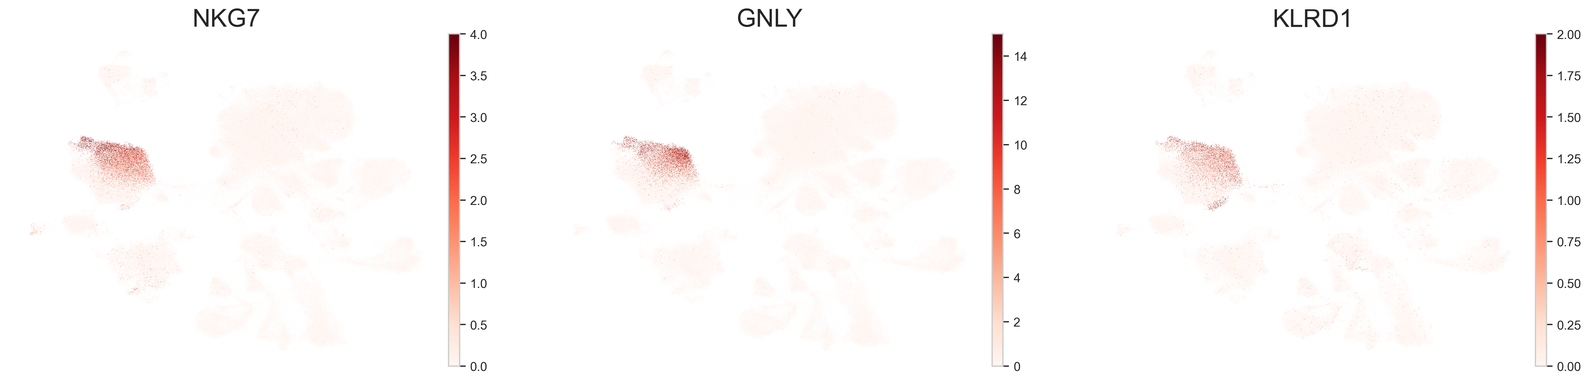

In [11]:
for ct in B_plasma_cts:
    print(f"{ct.upper()}:")
    sc.pl.umap(adata, color=marker_genes_in_data[ct], vmin=0, vmax="p99", sort_order=False, frameon=False, cmap="Reds"#colormaps https://matplotlib.org/stable/tutorials/colors/colormaps.html
    )
    print("\n\n\n")

In [12]:
B_plasma_markers = {
    ct: [m for m in ct_markers if m in adata.var.index]
    for ct, ct_markers in marker_genes.items()
    if ct in B_plasma_cts}

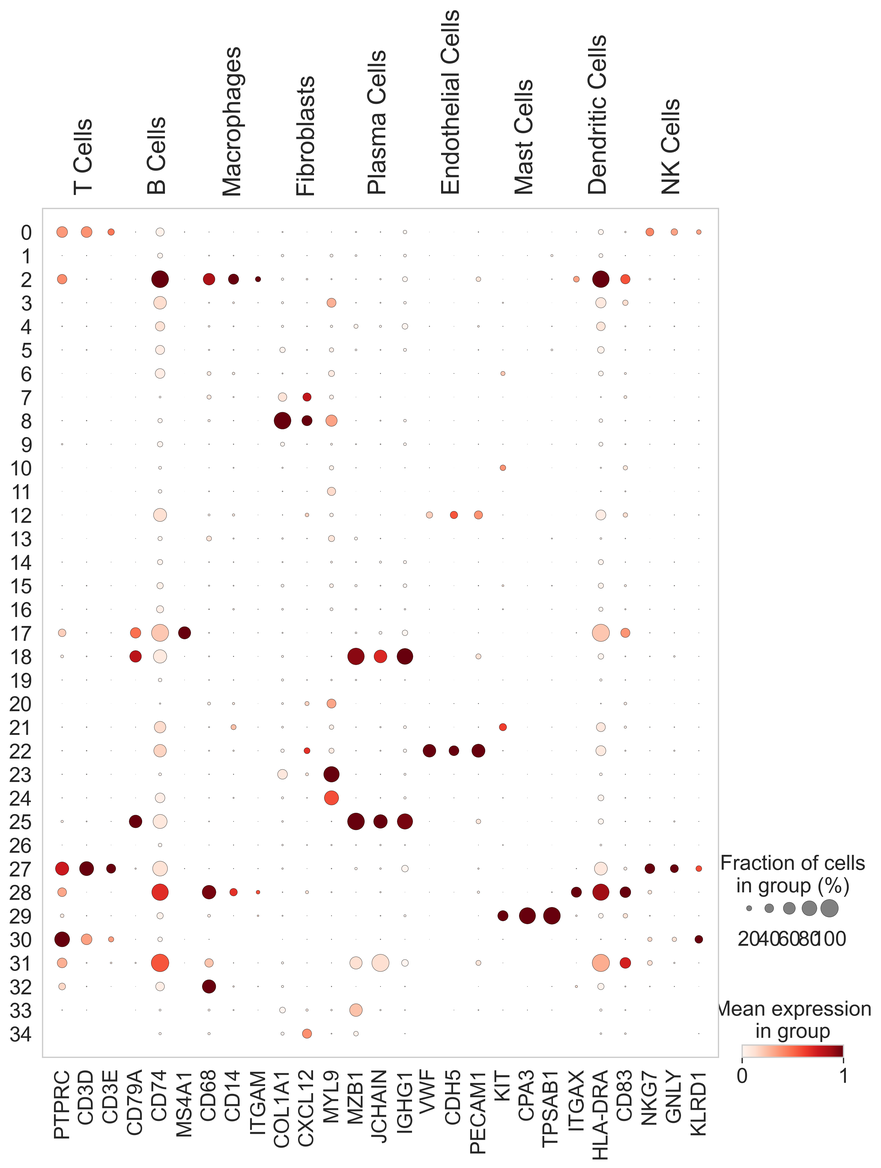

In [13]:
sc.pl.dotplot(adata, groupby="scVI_leiden", var_names=B_plasma_markers, standard_scale="var", show = False)#standard scale: normalize each gene to range from 0 to 1

plt.savefig(rf"{data_dir}/../Figures/5_Cell_Type_Marker.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
print(adata.X[:5, :5])
print(adata.raw)
print(adata.layers.keys())

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 0 stored elements and shape (5, 5)>
None
KeysView(Layers with keys: counts)


In [15]:
adata.layers["counts"][:5, :5].toarray()

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]], dtype=float32)

In [16]:
print(adata.X[:5, :5])
print(adata.layers)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 0 stored elements and shape (5, 5)>
Layers with keys: counts


In [17]:
#Marker dictionary
marker_genes = {
    "T Cells": ["PTPRC", "CD3D", "CD3E"],
    "B Cells": ["CD79A", "CD74", "MS4A1"],
    "Macrophages": ["CD68", "CD14", "ITGAM"],
    "Fibroblasts": ["COL1A1", "CXCL12", "MYL9"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHG1"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],
    "Mast Cells": ["KIT", "CPA3", "TPSAB1"],
    "Dendritic Cells": ["ITGAX", "HLA-DRA", "CD83"],
    "Epithelial Cells": ["KRT19", "EPCAM", "GAPDH"],
    "Tumour Cells": ["TP63", "KRT17"],
    "NK Cells": ["NKG7", "GNLY", "KLRD1"]
}

genes = sorted(set(
    gene
    for gene_list in marker_genes.values()
    for gene in gene_list
))

#keeping only genes present in dataset
genes_present = [g for g in genes if g in adata.var_names]

print(f"{len(genes_present)} / {len(genes)} genes found.")

32 / 32 genes found.


b) Celltypist Annotation

In [18]:
import anndata as ad
import celltypist
from celltypist import models

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Normalisation

In [19]:
adata_norm = ad.AnnData(X=adata.layers["counts"].copy(), obs=adata.obs.copy(), var=adata.var.copy())

#ensuring CSR sparse
if not sp.issparse(adata_norm.X):
    adata_norm.X = sp.csr_matrix(adata_norm.X)
elif not isinstance(adata_norm.X, sp.csr_matrix):
    adata_norm.X = adata_norm.X.tocsr()

#cellTypist normalization
sc.pp.normalize_total(adata_norm, target_sum=1e4)
sc.pp.log1p(adata_norm)

import gc
gc.collect()

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


27

In [20]:
import pybiomart
dataset = pybiomart.Dataset(name='hsapiens_gene_ensembl', host='http://www.ensembl.org')
mapping = dataset.query(attributes=['ensembl_gene_id', 'external_gene_name'])

#Symbol -> Ensembl ID dictionary
current_symbols = adata_norm.var_names.tolist()
mapping_clean = mapping.drop_duplicates(subset='Gene name')
symbol_to_ensembl = dict(zip(mapping_clean['Gene name'], mapping_clean['Gene stable ID']))

adata_norm.var['ensembl_id'] = adata_norm.var_names.map(symbol_to_ensembl)

n_mapped = adata_norm.var['ensembl_id'].notna().sum()
print(f"Successfully mapped: {n_mapped} / {adata_norm.n_vars} genes ({100*n_mapped/adata.n_vars:.1f}%)")

Successfully mapped: 22395 / 33538 genes (66.8%)


Model: Pal

In [23]:
import torch
use_gpu = torch.backends.mps.is_available() or torch.cuda.is_available()

#Pal model needs Ensembl IDs as var_names
mask = adata_norm.var["ensembl_id"].notna()
adata_pal = adata_norm[:, mask].copy()#subset, keep norm+log1p
adata_pal.var_names = adata_pal.var["ensembl_id"].astype(str)

pred_pal = celltypist.annotate(adata_pal, model=models.Model.load("Input_Dataframes/model_from_pal.pkl"), majority_voting=False)
del adata_pal
gc.collect()

⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 251616 cells and 22395 genes
🔗 Matching reference genes in the model
🧬 1301 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


773

In [24]:
del adata_norm
gc.collect()

0

In [25]:
adata.obs["celltypist_pal_label"]        = pred_pal.predicted_labels["predicted_labels"].values
adata.obs["celltypist_pal_conf"]         = pred_pal.probability_matrix.max(axis=1).values

#adata.obs["celltypist_immunehigh_label"] = pred_immunehigh.predicted_labels["majority_voting"].values
#adata.obs["celltypist_immunehigh_conf"]  = pred_immunehigh.probability_matrix.max(axis=1).values

#adata.obs["celltypist_immunelow_label"]  = pred_immunelow.predicted_labels["majority_voting"].values
#adata.obs["celltypist_immunelow_conf"]   = pred_immunelow.probability_matrix.max(axis=1).values

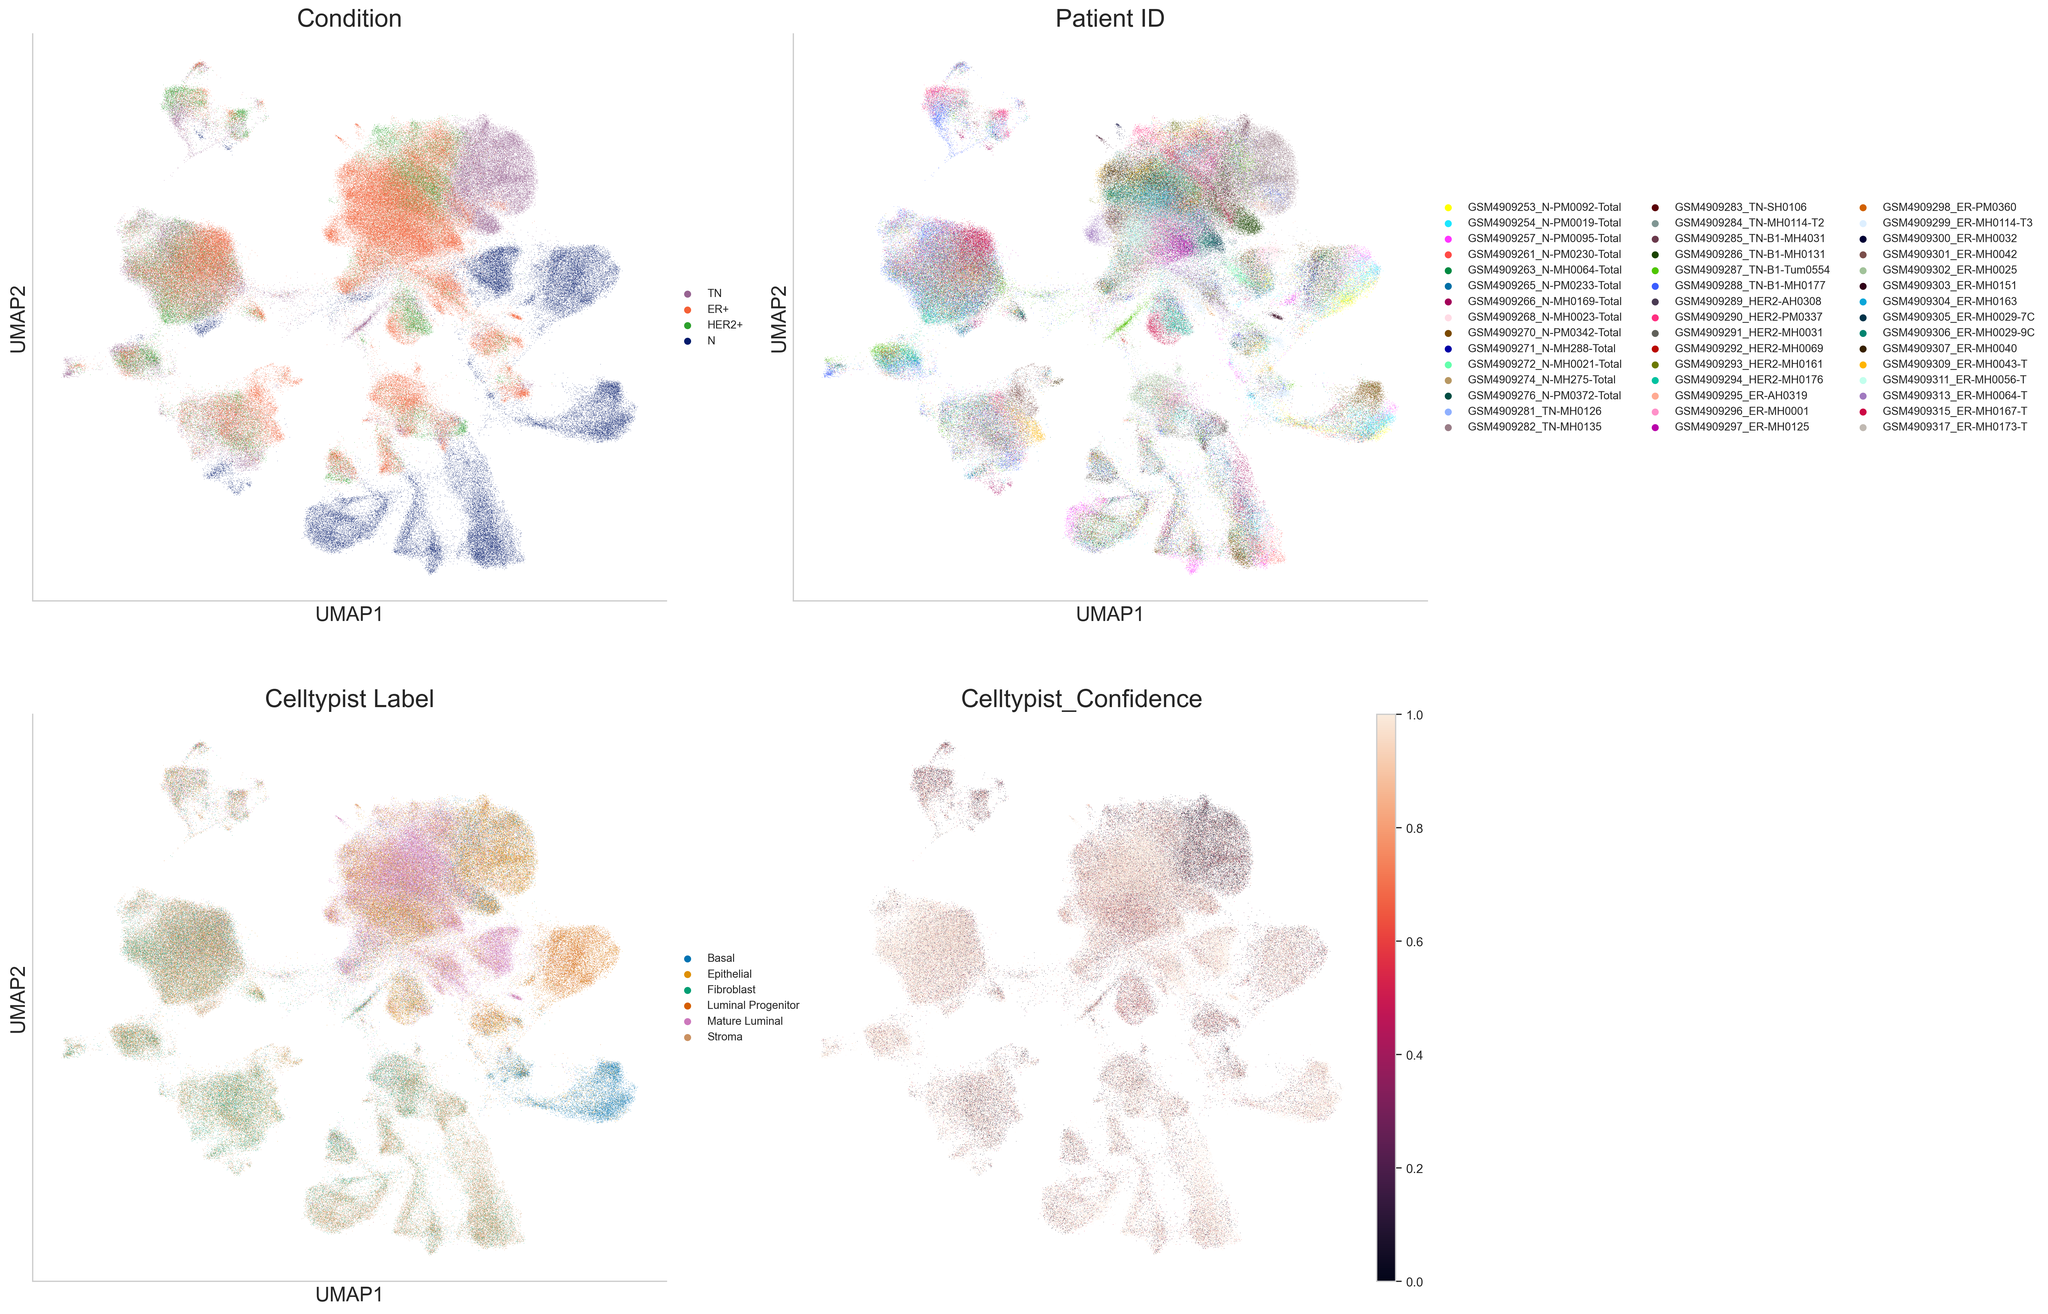

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
axes = axes.flatten()

#4a Condition
sc.pl.umap(adata, color="condition", ax=axes[0], layer="log1p", show=False)
axes[0].set_title("Condition")

#4b Patient
sc.pl.umap(adata, color="patient_id", ax=axes[1], layer="log1p", show=False)
axes[1].set_title("Patient ID")

#4c Celltypist label
sc.pl.umap(adata, color="celltypist_pal_label", ax=axes[2], layer="log1p",show=False)
axes[2].set_title("Celltypist Label")

#4d CNV Clusters
sc.pl.umap(adata, color="celltypist_pal_conf", frameon=False, ax=axes[3], layer="log1p", show=False)
axes[3].set_title("Celltypist_Confidence")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.savefig(rf"{data_dir}/../Figures/6_FIN_CellTypes.png", dpi=300, bbox_inches="tight")
plt.show()

Saving Progress from CellType Annotation

In [ ]:
import anndata as ad
import scipy.sparse as sp
import gc

#sanity checks
assert "counts" in adata.layers
assert "X_umap" in adata.obsm
assert "X_scVI" in adata.obsm

#creating annotation object
adata_annot = ad.AnnData(
    X=sp.csr_matrix(adata.layers["counts"]),#Raw counts
    obs=adata.obs.copy(), var=adata.var.copy()
)
adata_annot.layers["counts"] = adata_annot.X.copy()

#visualization layer only
if "log1p" in adata.layers:
    adata_annot.layers["log1p"] = adata.layers["log1p"].copy()

#embeddings
adata_annot.obsm["X_umap"] = adata.obsm["X_umap"]
adata_annot.obsm["X_scVI"] = adata.obsm["X_scVI"]

#metadata
adata_annot.obs["scVI_leiden"] = (adata.obs["scVI_leiden"].copy())
adata_annot.obs["celltypist_pal_label"] = (adata.obs["celltypist_pal_label"].copy())
adata_annot.obs["celltypist_pal_conf"] = (adata.obs["celltypist_pal_conf"].copy())

#saving
adata_annot.write_h5ad(rf"{data_dir}/../h5ad_saves/adata_annot.h5ad", compression="gzip")
print(adata_annot)

#cleanup
del adata
del adata_annot
gc.collect()

In [ ]:
automatic break -> Restart Kernel

STEP 5: Saving Epithelial Compartment

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

#loading files
data_dir = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # fallback
    "Unknown": "#808080"#grey
}

In [2]:
import psutil
import scanpy as sc

adata = sc.read_h5ad(rf"{data_dir}/../h5ad_saves/adata_annot.h5ad")
print(f"Available RAM: {psutil.virtual_memory().available / 1e9:.1f} GB")
print(adata)

Available RAM: 1.3 GB
AnnData object with n_obs × n_vars = 251616 × 33538
    obs: 'patient_id', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'sex_gene_expression', 'scDblFinder_score', 'scDblFinder_class', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'size_factors', 'sample', 'scVI_leiden', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf'
    var: 'highly_variable'
    obsm: 'X_scVI', 'X_umap'
    layers: 'counts'


In [3]:
#Manual Cluster Annotation
cl_annotation = {
    "0": "T Cells",
    "1": "Epithelial",
    "2": "Macrophages",
    "3": "Epithelial",
    "4": "Epithelial",
    "5": "Epithelial",
    "6": "Epithelial",
    "7": "Fibroblasts",
    "8": "Fibroblasts",
    "9": "Epithelial",
    "10": "Epithelial",
    "11": "Epithelial: Basal",
    "12": "Endothelial",
    "13": "Epithelial: Mature Luminal",
    "14": "Epithelial",
    "15": "Epithelial",
    "16": "Epithelial",
    "17": "B Cells",
    "18": "Plasma Cells",
    "19": "Epithelial",
    "20": "Fibroblasts",
    "21": "Epithelial",
    "22": "Endothelial",
    "23": "Fibroblasts",
    "24": "Epithelial",
    "25": "Plasma Cells",
    "26": "Epithelial",
    "27": "T Cells",
    "28": "Dendritic",
    "29": "Mast Cells",
    "30": "T Cells",
    "31": "B Cells",
    "32": "Macrophages",
    "33": "Epithelial",
    "34": "Epithelial",
}

adata.obs["cl_annotation"] = adata.obs["scVI_leiden"].map(cl_annotation)

In [4]:
#saving cell barcodes with metadata to CSV
adata.obs[["condition", "patient_id", "cl_annotation"]].to_csv(rf"{data_dir}/../csv_saves/cell_metadata.csv")

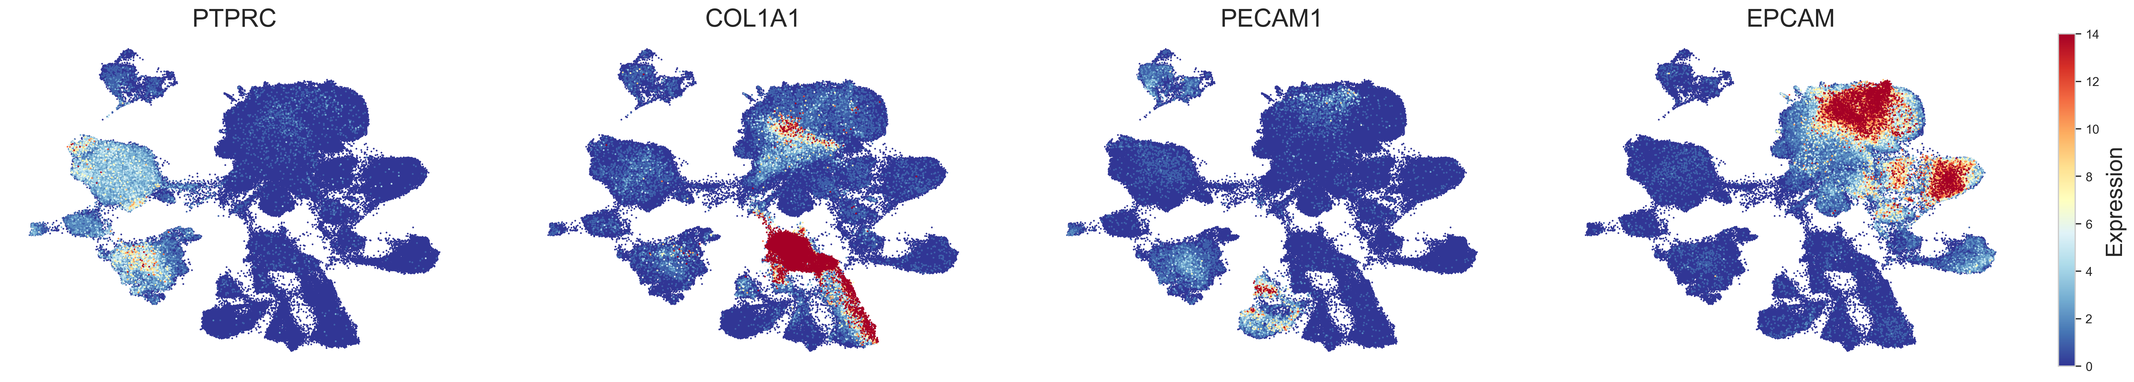

In [5]:
import matplotlib as mpl
import numpy as np
markers = ["PTPRC", "COL1A1", "PECAM1", "EPCAM"]

#computing shared vmax across all genes
vals = np.concatenate([adata[:, g].X.toarray().flatten() for g in markers])

vmax = np.percentile(vals, 99)

#5 UMAP coloured by compartment-defining genes
fig = sc.pl.umap(adata, color=markers, ncols=4, size=8, frameon=False, cmap="RdYlBu_r", vmin=0,
    vmax=vmax, sort_order=True, colorbar_loc=None, wspace=0.15, show=False, return_fig=True)

# Create shared colorbar
norm = mpl.colors.Normalize(vmin=0, vmax=vmax)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="RdYlBu_r")
sm.set_array([])

cbar = fig.colorbar(sm, ax=fig.axes, location="right", fraction=0.03, pad=0.02)

cbar.set_label("Expression", fontsize=18)
plt.savefig(rf"{data_dir}/../Figures/7_UMAP_marker_panels_BGR_SCALE.png", dpi=600, bbox_inches="tight")
plt.show()

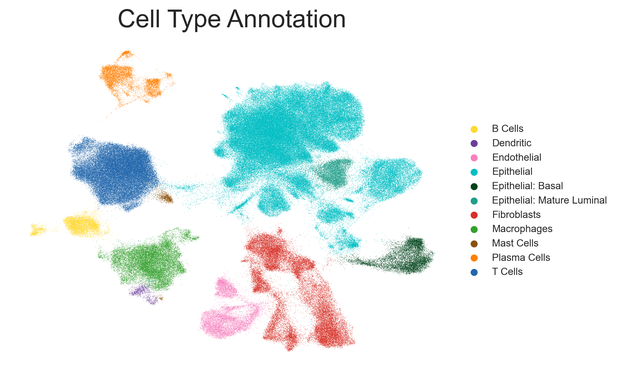

In [6]:
#6 UMAP coloured by Celltype
sc.pl.umap(adata, color="cl_annotation", palette=celltype_palette, layer="log1p", legend_loc="right margin", legend_fontsize=8, title="Cell Type Annotation", frameon=False, show=False)
plt.savefig(rf"{data_dir}/../Figures/8_Celltypes_N2.png", dpi=300, bbox_inches="tight")

In [7]:
import gc
gc.collect()

4493

Saving progress

In [8]:
# mapping clusters to annotation
adata.obs["cl_annotation"] = adata.obs["scVI_leiden"].map(cl_annotation)

# extracting all epithelial cells (any subtype) from all conditions
tumour_mask = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")

tumour_obs = adata.obs.loc[
    tumour_mask,
    ["patient_id", "condition", "cl_annotation", "scVI_leiden"]
].copy()

print(f"Tumour cells (all epithelial types): {tumour_mask.sum()}")
print(tumour_obs["cl_annotation"].value_counts())
print(tumour_obs["condition"].value_counts())
print(tumour_obs["patient_id"].value_counts())

tumour_obs.to_csv(rf"{data_dir}/../csv_saves/N_barcodes.csv")

Tumour cells (all epithelial types): 140645
cl_annotation
Epithelial                    126014
Epithelial: Basal               8051
Epithelial: Mature Luminal      6580
Name: count, dtype: int64
condition
ER+      65410
TN       29291
N        27637
HER2+    18307
Name: count, dtype: int64
patient_id
GSM4909282_TN-MH0135         12967
GSM4909306_ER-MH0029-9C       6438
GSM4909299_ER-MH0114-T3       5980
GSM4909297_ER-MH0125          5578
GSM4909307_ER-MH0040          5463
GSM4909294_HER2-MH0176        5444
GSM4909304_ER-MH0163          5438
GSM4909296_ER-MH0001          5374
GSM4909286_TN-B1-MH0131       5161
GSM4909315_ER-MH0167-T        4867
GSM4909285_TN-B1-MH4031       4817
GSM4909302_ER-MH0025          4640
GSM4909270_N-PM0342-Total     4576
GSM4909268_N-MH0023-Total     4541
GSM4909293_HER2-MH0161        4172
GSM4909254_N-PM0019-Total     4076
GSM4909290_HER2-PM0337        3533
GSM4909313_ER-MH0064-T        3424
GSM4909289_HER2-AH0308        3308
GSM4909253_N-PM0092-Total     323

In [9]:
#mapping clusters to annotation
adata.obs["cl_annotation"] = adata.obs["scVI_leiden"].map(cl_annotation)

#extracting epithelial cells from all conditions
tumour_mask = (
    adata.obs["cl_annotation"].isin(["Epithelial"])
)
tumour_obs = adata.obs.loc[
    tumour_mask,
    ["patient_id", "condition", "cl_annotation", "scVI_leiden"]
].copy()
print(f"Tumour cells (excl. N): {tumour_mask.sum()}")

normal_epithelial = (
    adata.obs["cl_annotation"].isin([
        "Epithelial: Luminal Progenitor",
        "Epithelial: Mature Luminal",
        "Epithelial: Basal",
        "Epithelial"
    ])
)

print("Before CNV filter:", normal_epithelial.sum())

tumour_obs = adata.obs.loc[tumour_mask, ["patient_id", "condition", "cl_annotation", "scVI_leiden"]].copy()

print(f"Tumour cells{tumour_mask.sum()}")
print(tumour_obs["condition"].value_counts())
print(tumour_obs["patient_id"].value_counts())

tumour_obs.to_csv(rf"{data_dir}/../csv_saves/N_barcodes.csv")

Tumour cells (excl. N): 126014
Before CNV filter: 140645
Tumour cells126014
condition
ER+      65215
TN       29258
HER2+    18263
N        13278
Name: count, dtype: int64
patient_id
GSM4909282_TN-MH0135         12957
GSM4909306_ER-MH0029-9C       6400
GSM4909299_ER-MH0114-T3       5975
GSM4909297_ER-MH0125          5567
GSM4909307_ER-MH0040          5462
GSM4909294_HER2-MH0176        5436
GSM4909304_ER-MH0163          5429
GSM4909296_ER-MH0001          5346
GSM4909286_TN-B1-MH0131       5160
GSM4909315_ER-MH0167-T        4858
GSM4909285_TN-B1-MH4031       4813
GSM4909302_ER-MH0025          4587
GSM4909293_HER2-MH0161        4169
GSM4909290_HER2-PM0337        3527
GSM4909313_ER-MH0064-T        3417
GSM4909289_HER2-AH0308        3294
GSM4909287_TN-B1-Tum0554      3127
GSM4909311_ER-MH0056-T        3077
GSM4909309_ER-MH0043-T        2922
GSM4909317_ER-MH0173-T        2858
GSM4909301_ER-MH0042          2839
GSM4909305_ER-MH0029-7C       2249
GSM4909298_ER-PM0360          2090
GSM4909254_N

In [ ]:
deliberate break

ENDE